# Full-Fledged EDA + ML Project: Loan Default Prediction

# PROJECT STRUCTURE OVERVIEW
1. **PHASE 1**  → Data Ingestion & Schema Setup (+ Versioning + Logging tables)
2. **PHASE 2**  → Exploratory Data Analysis (EDA)
3. **PHASE 3**  → Data Cleaning & Preprocessing
4. **PHASE 4**  → Feature Engineering
5. **PHASE 5**  → Model Training (Logistic Reg, Random Forest, XGBoost) with Versioning
6. **PHASE 6**  → Model Evaluation Reports (Comparative Leaderboard)
7. **PHASE 7**  → Hyperparameter Tuning
8. **PHASE 8**  → Final Predictions & Serving with Logging
9. **PHASE 9**  → Model Explainability
10. **PHASE 10** → Flask Prediction API (Python)
11. **PHASE 11** → Cleanup

# PHASE 1: Data Ingestion, Model Registry & Logging Setup

## 1A. Create Schema
```sql
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project`
OPTIONS(
  location = 'US',
  description = 'Full EDA + ML Project: Loan Default Prediction with Versioning & Logging'
);
```

---
> gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default

## 1B. Create Model Registry (Version Tracking Table)
```sql
-- Registry table for tracking all model versions
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry` (
  model_id STRING,
  model_name STRING,
  model_type STRING,
  version STRING,
  training_timestamp TIMESTAMP,
  training_dataset STRING,
  hyperparameters STRING,
  status STRING,
  notes STRING
);
```
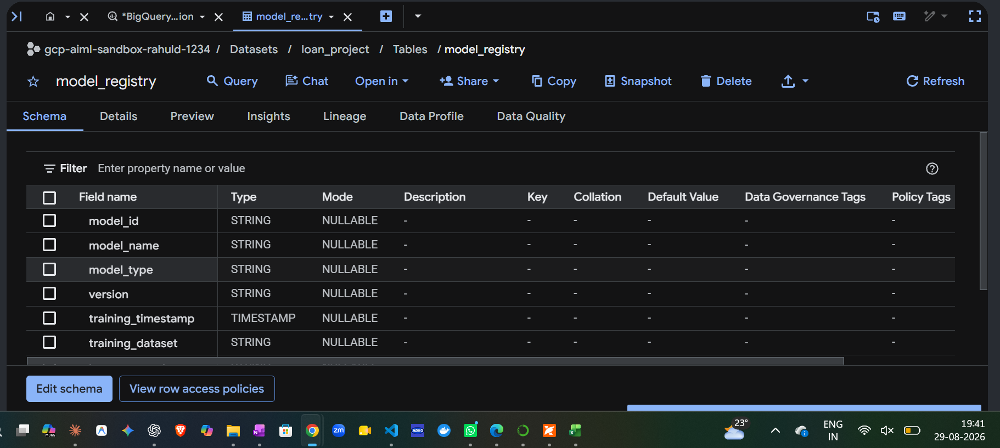

---
## 1C. Create Prediction Log Table
```sql
-- Log every prediction call made via API or batch
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.prediction_logs` (
  log_id STRING,
  request_timestamp TIMESTAMP,
  model_used STRING,
  model_version STRING,
  input_features JSON,
  predicted_class STRING,
  predicted_probability FLOAT64,
  source STRING          -- 'API', 'BATCH', 'DASHBOARD'
);
```
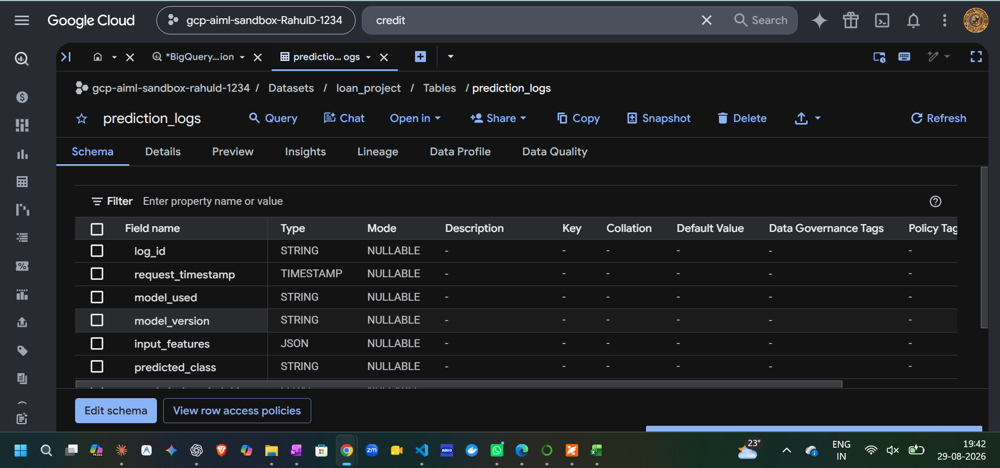

---
## 1D. Create Training Log Table
```sql
-- Log every model training run
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs` (
  log_id STRING,
  training_timestamp TIMESTAMP,
  model_name STRING,
  model_version STRING,
  duration_message STRING,
  event_status STRING,   -- 'STARTED', 'SUCCESS', 'FAILED'
  event_message STRING
);
```
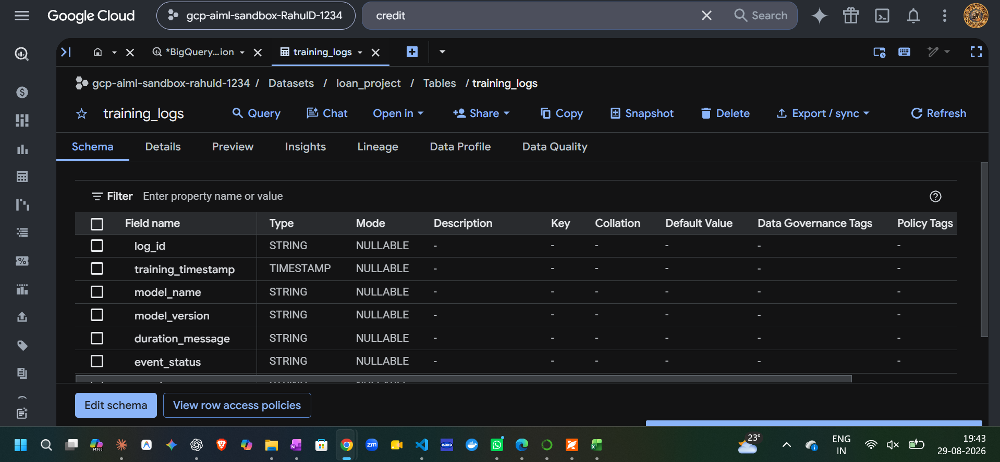

---
## 1E. Verify Raw Data Loaded
```sql
SELECT
  COUNT(*) AS total_rows,
  COUNT(DISTINCT ID) AS unique_loans
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;
```
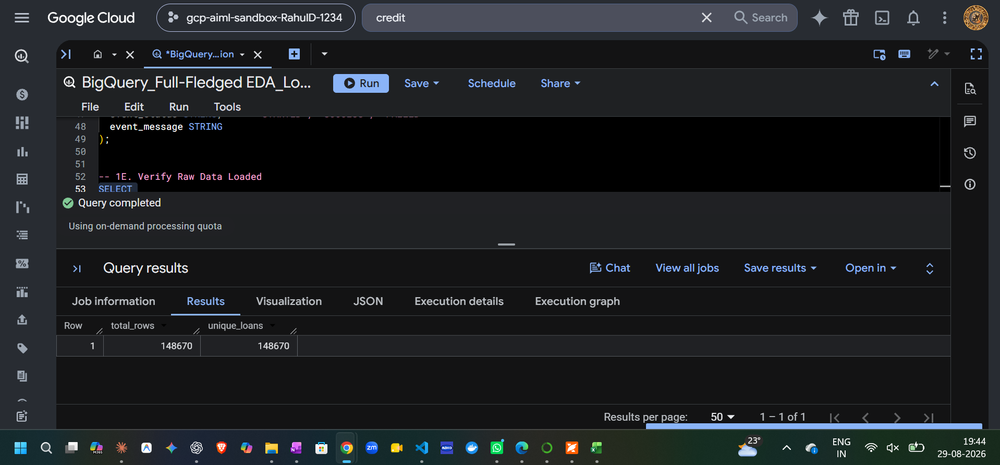

---

# PHASE 2: Exploratory Data Analysis (EDA)

## 2A. Column Null Overview
```sql
SELECT
  COUNT(*) AS total_rows,
  COUNTIF(Status IS NULL) AS null_Status,
  COUNTIF(loan_amount IS NULL) AS null_loan_amount,
  COUNTIF(income IS NULL) AS null_income,
  COUNTIF(Credit_Score IS NULL) AS null_credit_score,
  COUNTIF(loan_type IS NULL) AS null_loan_type,
  COUNTIF(loan_purpose IS NULL) AS null_loan_purpose,
  COUNTIF(term IS NULL) AS null_term
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;
```
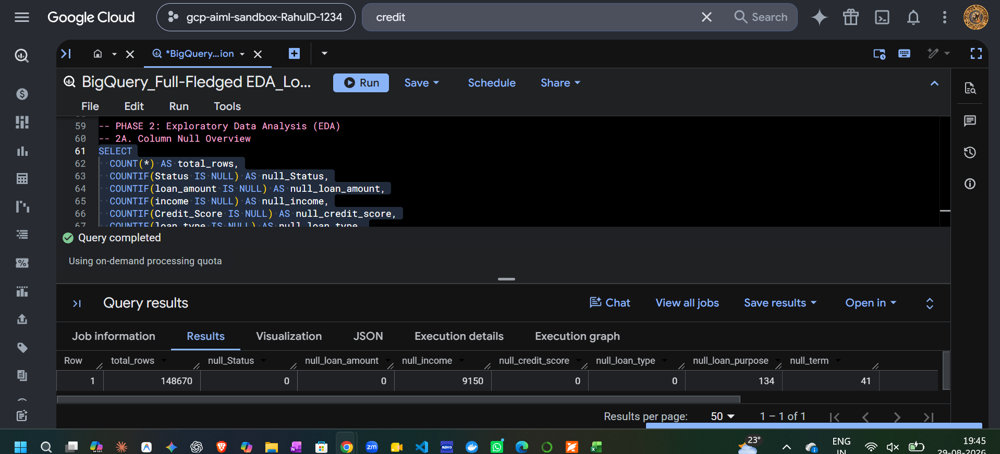

---
## 2B. Target Class Distribution
```sql
SELECT
  Status,
  COUNT(*) AS loan_count,
  ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS percentage
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
GROUP BY Status
ORDER BY loan_count DESC;
```
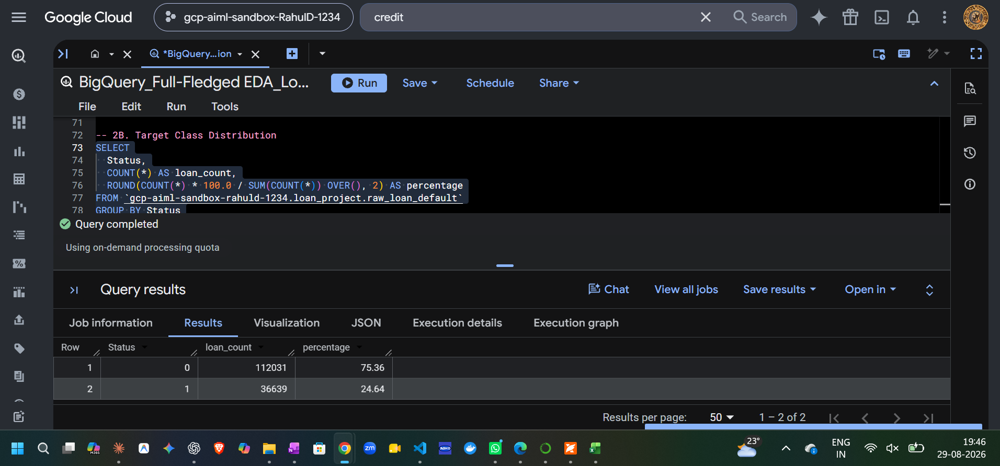

---
## 2C. Numeric Feature Statistics
```sql
SELECT 'loan_amount' AS feature,
  ROUND(AVG(loan_amount), 2) AS mean,
  APPROX_QUANTILES(loan_amount, 2)[OFFSET(1)] AS median,
  ROUND(STDDEV(loan_amount), 2) AS std_dev,
  MIN(loan_amount) AS min_val, MAX(loan_amount) AS max_val
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
UNION ALL
SELECT 'income',
  ROUND(AVG(income), 2), APPROX_QUANTILES(income, 2)[OFFSET(1)],
  ROUND(STDDEV(income), 2), MIN(income), MAX(income)
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
UNION ALL
SELECT 'Credit_Score',
  ROUND(AVG(Credit_Score), 2), APPROX_QUANTILES(Credit_Score, 2)[OFFSET(1)],
  ROUND(STDDEV(Credit_Score), 2), MIN(Credit_Score), MAX(Credit_Score)
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;
```
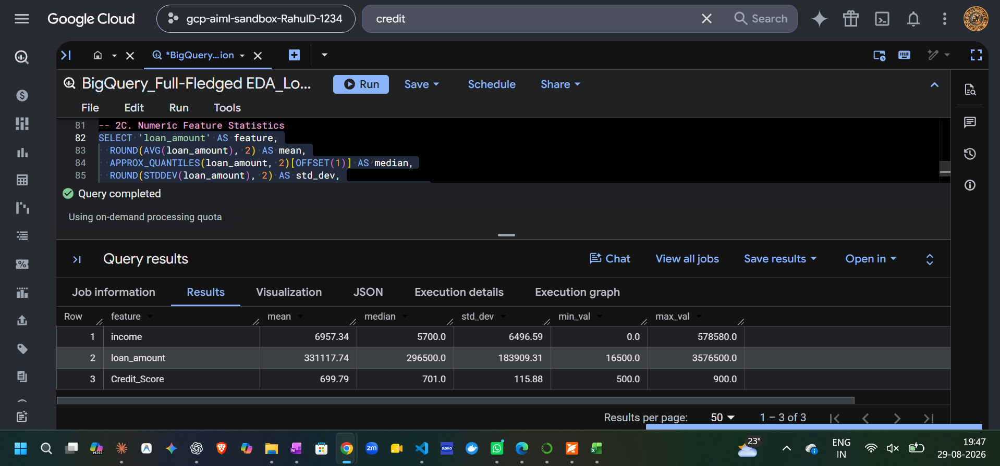

---
## 2D. Default Rate by Loan Purpose
```sql
SELECT
  loan_purpose,
  COUNT(*) AS total_loans,
  COUNTIF(CAST(Status AS INT64) = 1) AS default_count,
  ROUND(COUNTIF(CAST(Status AS INT64) = 1) * 100.0 / COUNT(*), 2) AS default_rate_pct
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
WHERE loan_purpose IS NOT NULL
GROUP BY loan_purpose
ORDER BY default_rate_pct DESC;
```
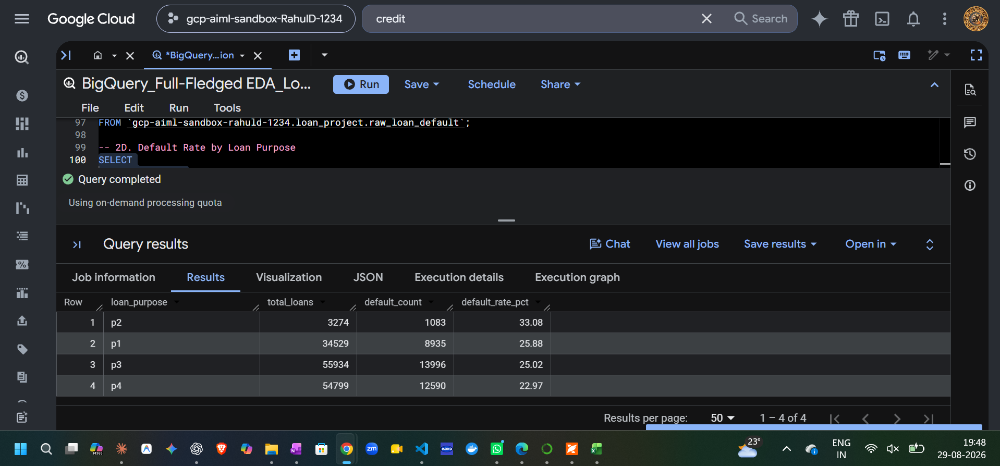

---
## 2E. Outlier Detection (IQR on loan_amount)
```sql
WITH stats AS (
  SELECT
    APPROX_QUANTILES(loan_amount, 4)[OFFSET(1)] AS q1,
    APPROX_QUANTILES(loan_amount, 4)[OFFSET(3)] AS q3
  FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
  WHERE loan_amount IS NOT NULL
)
SELECT
  COUNT(*) AS total_records,
  COUNTIF(t.loan_amount < (s.q1 - 1.5 * (s.q3 - s.q1)) 
       OR t.loan_amount > (s.q3 + 1.5 * (s.q3 - s.q1))) AS outlier_count,
  ROUND(ANY_VALUE(s.q1), 2) AS q1,
  ROUND(ANY_VALUE(s.q3), 2) AS q3,
  ROUND(ANY_VALUE(s.q1 - 1.5 * (s.q3 - s.q1)), 2) AS lower_bound,
  ROUND(ANY_VALUE(s.q3 + 1.5 * (s.q3 - s.q1)), 2) AS upper_bound
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default` t
CROSS JOIN stats s;
```
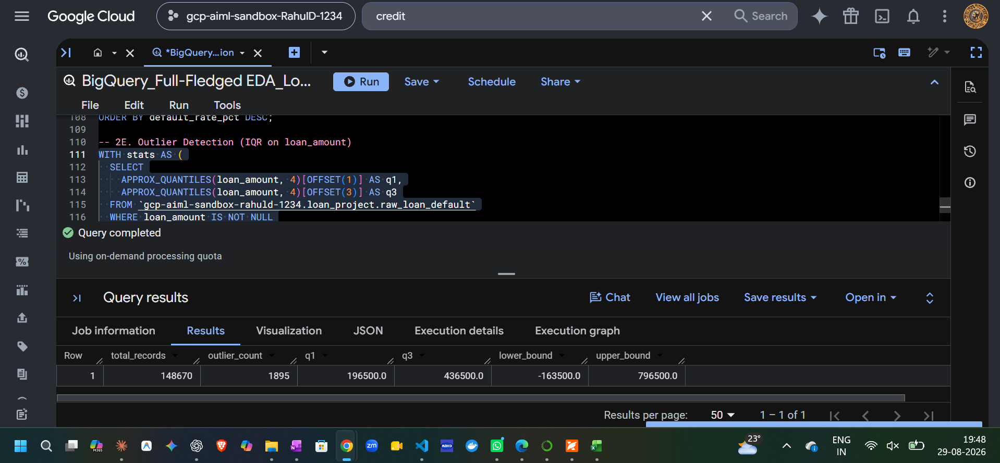

---
## 2F. Correlation Analysis
```sql
SELECT
  ROUND(CORR(loan_amount, CAST(Status AS INT64)), 4) AS corr_loan_amount,
  ROUND(CORR(income, CAST(Status AS INT64)), 4) AS corr_income,
  ROUND(CORR(Credit_Score, CAST(Status AS INT64)), 4) AS corr_credit_score,
  ROUND(CORR(rate_of_interest, CAST(Status AS INT64)), 4) AS corr_interest_rate,
  ROUND(CORR(LTV, CAST(Status AS INT64)), 4) AS corr_ltv
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;
```
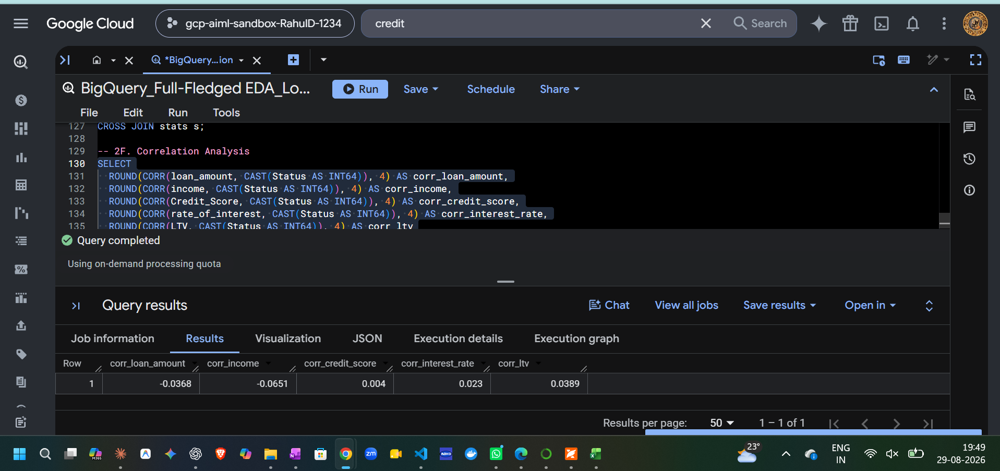

---

# PHASE 3: Data Cleaning & Preprocessing
```sql
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.cleaned_loan` AS
WITH medians AS (
  SELECT
    APPROX_QUANTILES(loan_amount, 2)[OFFSET(1)] AS med_loan_amount,
    APPROX_QUANTILES(income, 2)[OFFSET(1)] AS med_income,
    APPROX_QUANTILES(Credit_Score, 2)[OFFSET(1)] AS med_credit_score,
    APPROX_QUANTILES(rate_of_interest, 2)[OFFSET(1)] AS med_interest,
    APPROX_QUANTILES(LTV, 2)[OFFSET(1)] AS med_ltv,
    APPROX_QUANTILES(term, 2)[OFFSET(1)] AS med_term
  FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`
)
SELECT
  -- Target Label
  CAST(Status AS STRING) AS Status,
  
  -- Numeric Features (Missing values imputed with median)
  COALESCE(loan_amount, (SELECT med_loan_amount FROM medians)) AS loan_amount,
  COALESCE(income, (SELECT med_income FROM medians)) AS income,
  COALESCE(Credit_Score, (SELECT med_credit_score FROM medians)) AS Credit_Score,
  COALESCE(rate_of_interest, (SELECT med_interest FROM medians)) AS rate_of_interest,
  COALESCE(LTV, (SELECT med_ltv FROM medians)) AS LTV,
  COALESCE(term, (SELECT med_term FROM medians)) AS term,
  
  -- Categorical Features (Missing → 'Unknown')
  COALESCE(CAST(loan_type AS STRING), 'Unknown') AS loan_type,
  COALESCE(CAST(loan_purpose AS STRING), 'Unknown') AS loan_purpose,
  COALESCE(CAST(business_or_commercial AS STRING), 'Unknown') AS business_or_commercial,
  COALESCE(CAST(Neg_ammortization AS STRING), 'Unknown') AS Neg_ammortization,
  COALESCE(CAST(interest_only AS STRING), 'Unknown') AS interest_only,
  COALESCE(CAST(lump_sum_payment AS STRING), 'Unknown') AS lump_sum_payment,
  COALESCE(CAST(credit_type AS STRING), 'Unknown') AS credit_type,
  
  -- FIXED: Added backticks around the hyphenated source column, and aliased with underscores
  COALESCE(CAST(`co-applicant_credit_type` AS STRING), 'Unknown') AS co_applicant_credit_type,
  
  COALESCE(CAST(age AS STRING), 'Unknown') AS age,
  COALESCE(CAST(Region AS STRING), 'Unknown') AS Region
FROM
  `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;
```
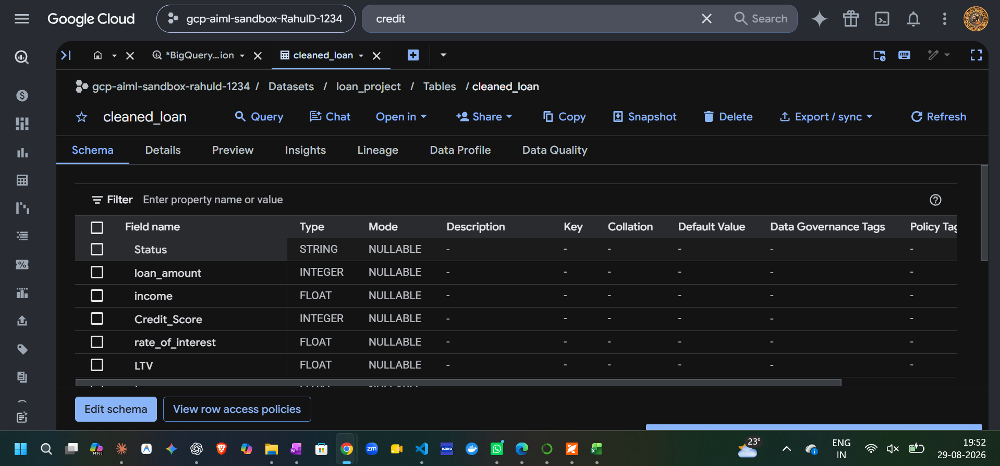

--- 

# PHASE 4: Feature Engineering
```sql
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan` AS
SELECT
  *,
  -- Feature 1: Debt-to-Income Ratio
  SAFE_DIVIDE(loan_amount, NULLIF(income, 0)) AS debt_to_income_ratio,
  
  -- Feature 2: Loan Amount Bucket
  CASE
    WHEN loan_amount <= 100000 THEN 'Small'
    WHEN loan_amount <= 300000 THEN 'Medium'
    WHEN loan_amount <= 500000 THEN 'Large'
    ELSE 'Jumbo'
  END AS loan_size_bucket,
  
  -- Feature 3: Credit Score Category
  CASE
    WHEN Credit_Score < 580 THEN 'Poor'
    WHEN Credit_Score < 670 THEN 'Fair'
    WHEN Credit_Score < 740 THEN 'Good'
    WHEN Credit_Score < 800 THEN 'Very Good'
    ELSE 'Excellent'
  END AS credit_score_tier,
  
  -- Feature 4: High LTV flag
  IF(LTV > 80, 'HighRisk', 'LowRisk') AS ltv_risk_flag,
  
  -- Feature 5: Monthly EMI approximation (Simple)
  ROUND(SAFE_DIVIDE(loan_amount * (1 + rate_of_interest / 100), NULLIF(term, 0)), 2) AS approx_monthly_emi
FROM
  `gcp-aiml-sandbox-rahuld-1234.loan_project.cleaned_loan`;
```
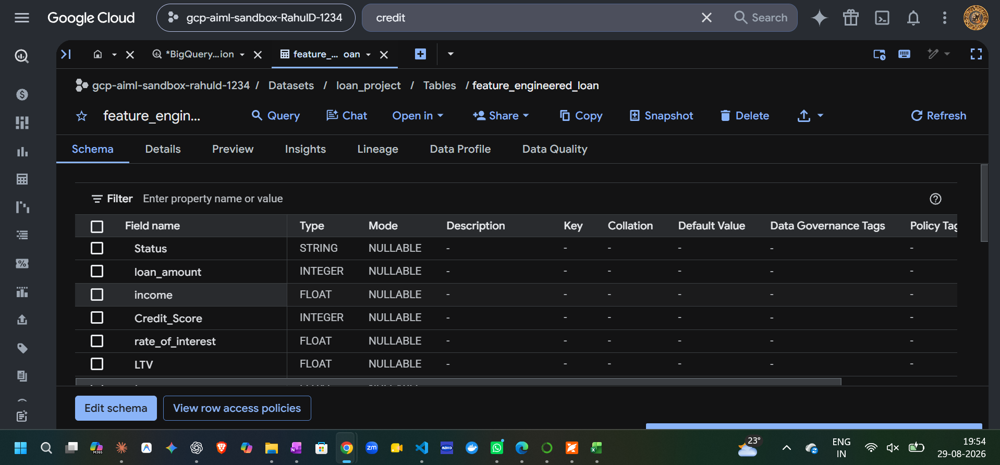



---

# PHASE 5: Model Training (Versioned + Logged)

## 5A. Logistic Regression V1
```sql
-- Log Training Start
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(
  GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_logistic', 'v1', NULL, 'STARTED', 'Logistic Regression v1 training initiated'
);

-- Train Model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_logistic_v1`
OPTIONS (
  model_type = 'LOGISTIC_REG',
  input_label_cols = ['Status'],
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE,
  l2_reg = 0.5
) AS
SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`;

-- Register Version
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry`
VALUES (
  GENERATE_UUID(), 'model_logistic', 'LOGISTIC_REG', 'v1',
  CURRENT_TIMESTAMP(), 'feature_engineered_loan',
  '{"l2_reg":0.5, "auto_class_weights":true}',
  'ACTIVE', 'Baseline logistic regression v1'
);

-- Log Success
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(
  GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_logistic', 'v1', NULL, 'SUCCESS', 'Logistic Regression v1 trained successfully'
);
```
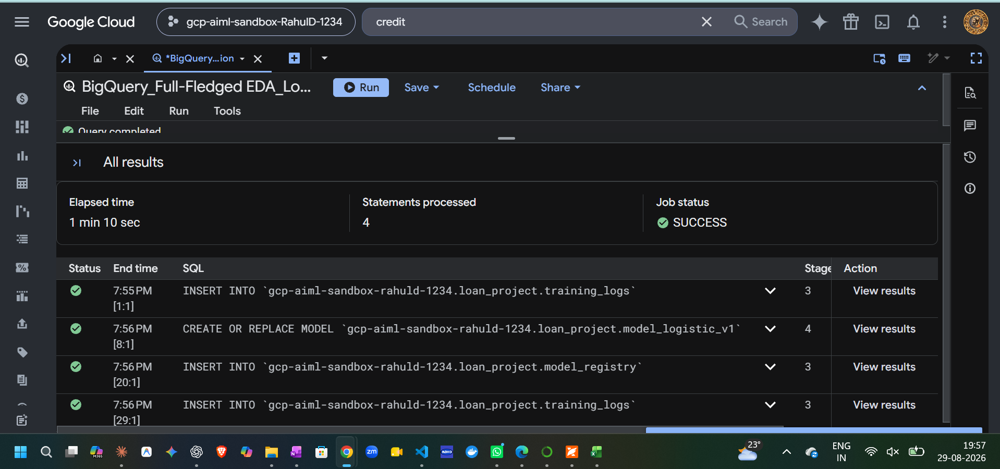

---
## 5B. Train Random Forest V1
```sql
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_random_forest', 'v1', NULL, 'STARTED', 'Random Forest v1 training initiated');

CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_random_forest_v1`
OPTIONS (
  model_type = 'RANDOM_FOREST_CLASSIFIER',
  input_label_cols = ['Status'],
  num_parallel_tree = 20,
  max_tree_depth = 6,
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`;

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry`
VALUES (
  GENERATE_UUID(), 'model_random_forest', 'RANDOM_FOREST_CLASSIFIER', 'v1',
  CURRENT_TIMESTAMP(), 'feature_engineered_loan',
  '{"num_parallel_tree":20, "max_tree_depth":6}',
  'ACTIVE', 'Baseline random forest v1'
);

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_random_forest', 'v1', NULL, 'SUCCESS', 'Random Forest v1 trained successfully');
```
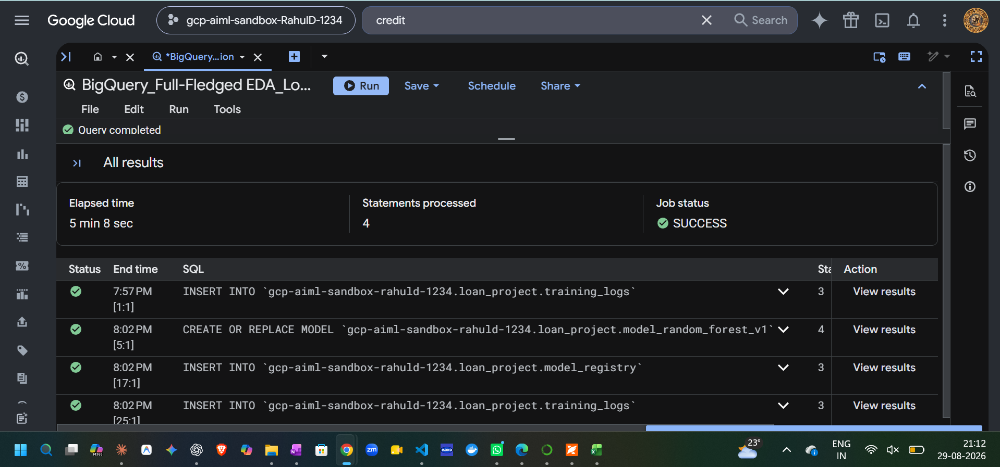


---
## 5C. Train XGBoost V1
```sql
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_xgboost', 'v1', NULL, 'STARTED', 'XGBoost v1 training initiated');

CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v1`
OPTIONS (
  model_type = 'BOOSTED_TREE_CLASSIFIER',
  input_label_cols = ['Status'],
  max_iterations = 50,
  learn_rate = 0.08,
  max_tree_depth = 5,
  subsample = 0.80,
  early_stop = TRUE,
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`;

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry`
VALUES (
  GENERATE_UUID(), 'model_xgboost', 'BOOSTED_TREE_CLASSIFIER', 'v1',
  CURRENT_TIMESTAMP(), 'feature_engineered_loan',
  '{"max_iterations":50, "learn_rate":0.08, "max_tree_depth":5, "subsample":0.80}',
  'ACTIVE', 'Baseline XGBoost v1'
);

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_xgboost', 'v1', NULL, 'SUCCESS', 'XGBoost v1 trained successfully');
```
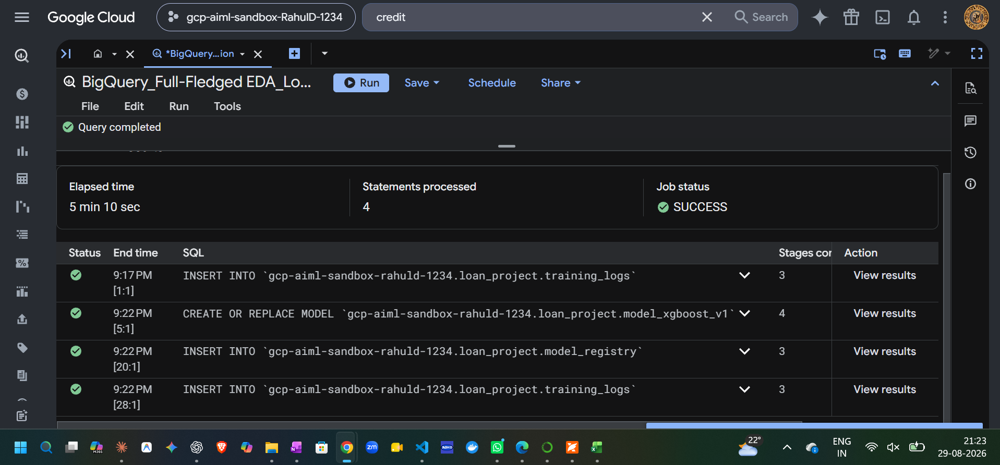

---

# PHASE 6: Model Evaluation & Comparative Reports

## 6A. Save Model Comparison Report Table
```sql
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.model_evaluation_reports` AS
SELECT 
  'Logistic Regression' AS model_name, 'v1' AS version, CURRENT_TIMESTAMP() AS evaluated_at, * 
FROM ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_logistic_v1`)
UNION ALL
SELECT 
  'Random Forest', 'v1', CURRENT_TIMESTAMP(), * 
FROM ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_random_forest_v1`)
UNION ALL
SELECT 
  'XGBoost', 'v1', CURRENT_TIMESTAMP(), * 
FROM ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v1`);
```
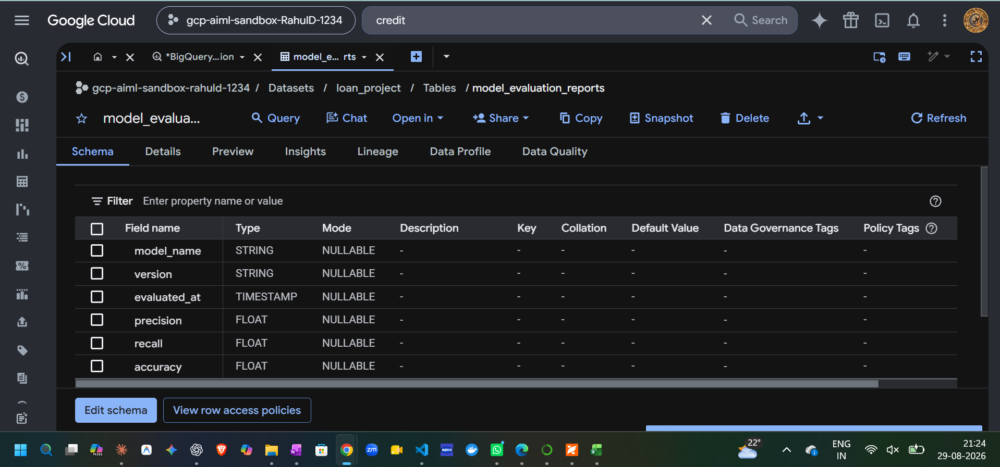

---
## 6B. View Report (Leaderboard, sorted by AUC)
```sql
SELECT 
  model_name, version,
  ROUND(accuracy, 4) AS accuracy,
  ROUND(precision, 4) AS precision,
  ROUND(recall, 4) AS recall,
  ROUND(f1_score, 4) AS f1_score,
  ROUND(roc_auc, 4) AS roc_auc,
  ROUND(log_loss, 4) AS log_loss,
  evaluated_at
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.model_evaluation_reports`
ORDER BY roc_auc DESC;
```
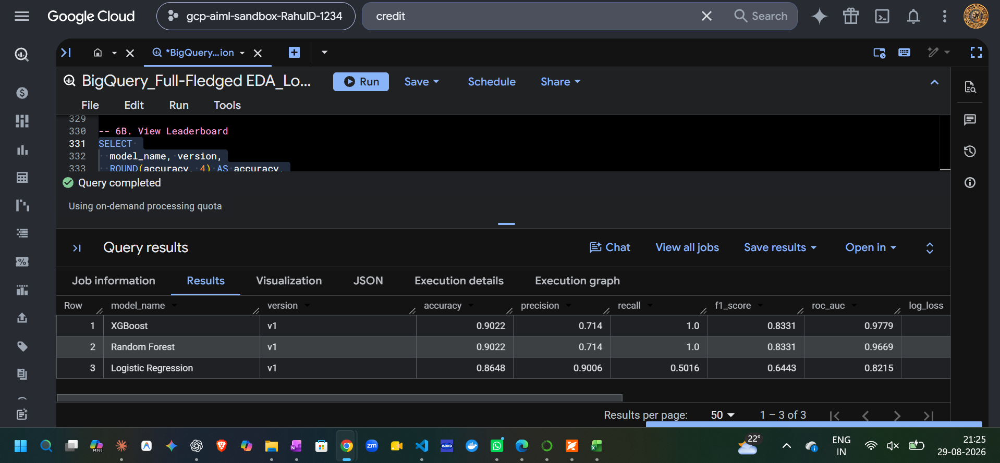

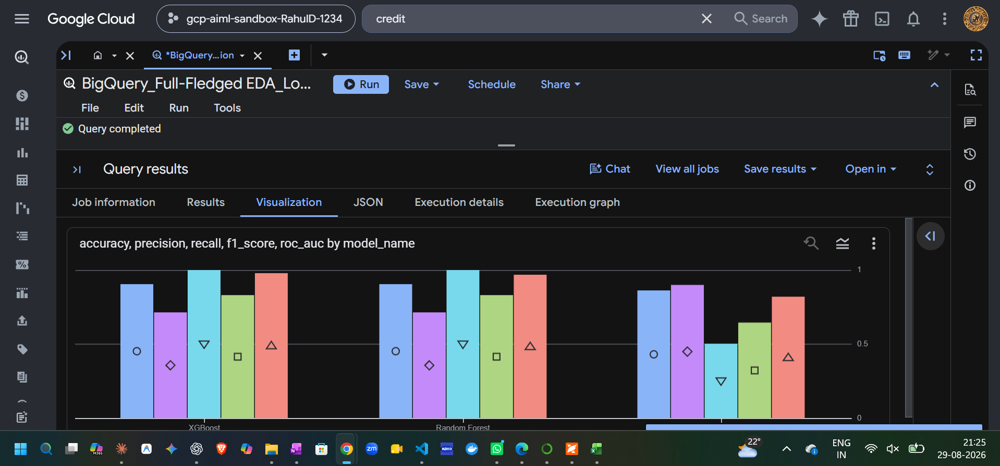

---
## 6C. Confusion Matrix Reports for All 3 Models
```sql
SELECT 'Logistic Regression' AS model_name, * FROM 
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_logistic_v1`)
UNION ALL
SELECT 'Random Forest', * FROM 
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_random_forest_v1`)
UNION ALL
SELECT 'XGBoost', * FROM 
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v1`);
```
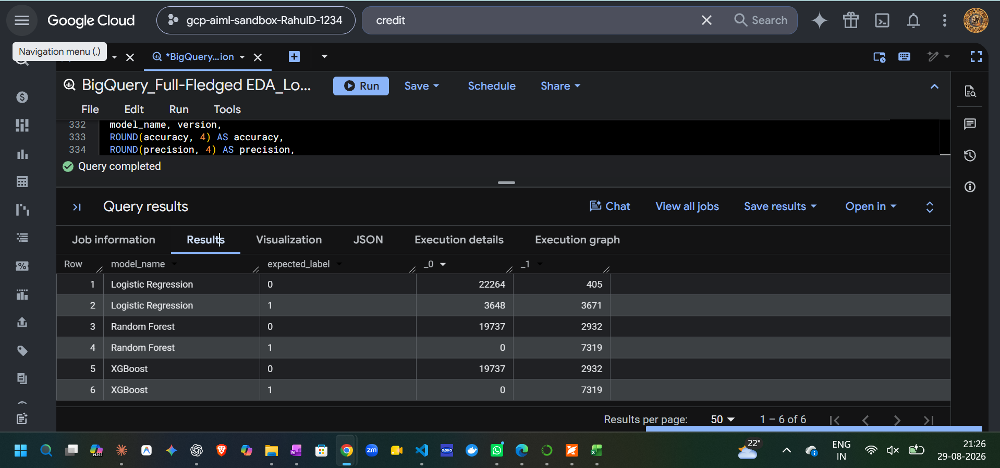

---

## PHASE 7: Hyperparameter Tuning (Creates XGBoost V2)
```sql
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_xgboost', 'v2', NULL, 'STARTED', 'XGBoost v2 HPO tuning started');

CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`
OPTIONS (
  model_type = 'BOOSTED_TREE_CLASSIFIER',
  input_label_cols = ['Status'],
  num_trials = 8,
  max_parallel_trials = 2,
  hparam_tuning_algorithm = 'VIZIER_DEFAULT',
  hparam_tuning_objectives = ['ROC_AUC'],
  learn_rate = HPARAM_RANGE(0.01, 0.3),
  max_tree_depth = HPARAM_CANDIDATES([3, 5, 7]),
  subsample = HPARAM_RANGE(0.6, 1.0),
  l1_reg = HPARAM_RANGE(0.0, 5.0),
  l2_reg = HPARAM_RANGE(0.0, 5.0),
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`;

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry`
VALUES (
  GENERATE_UUID(), 'model_xgboost', 'BOOSTED_TREE_CLASSIFIER', 'v2',
  CURRENT_TIMESTAMP(), 'feature_engineered_loan',
  '{"hpo":true, "num_trials":8, "objective":"ROC_AUC"}',
  'ACTIVE', 'Hyperparameter-tuned XGBoost v2'
);

INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`
VALUES(GENERATE_UUID(), CURRENT_TIMESTAMP(),
  'model_xgboost', 'v2', NULL, 'SUCCESS', 'XGBoost v2 tuning completed');
```
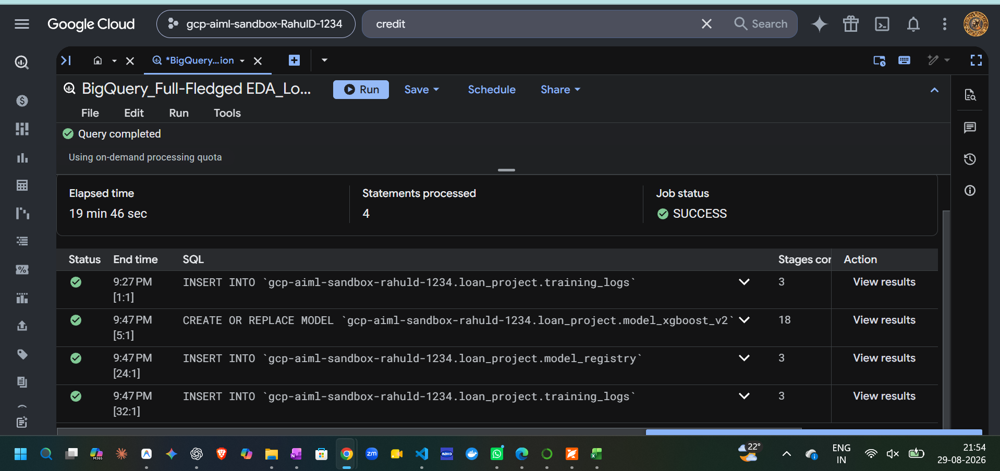

---

# View Best Trial
```sql
SELECT *
FROM ML.TRIAL_INFO(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`)
ORDER BY is_optimal DESC, trial_id ASC;
```
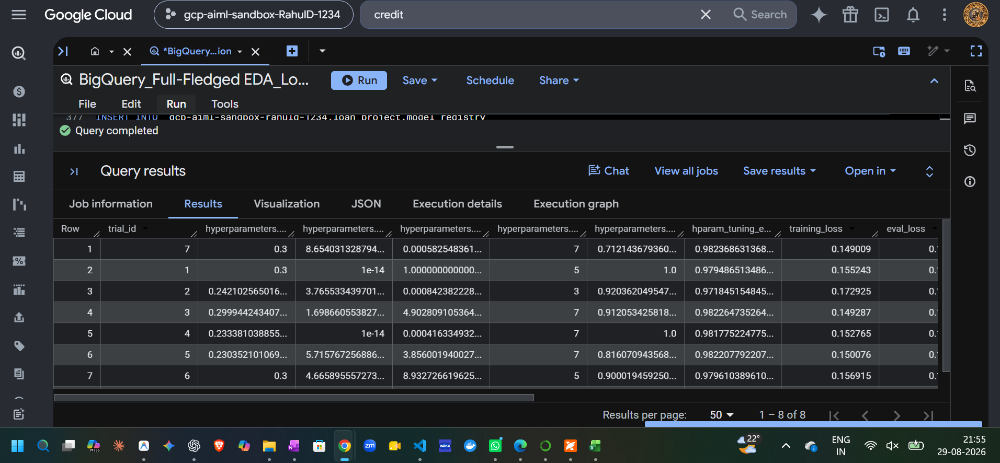

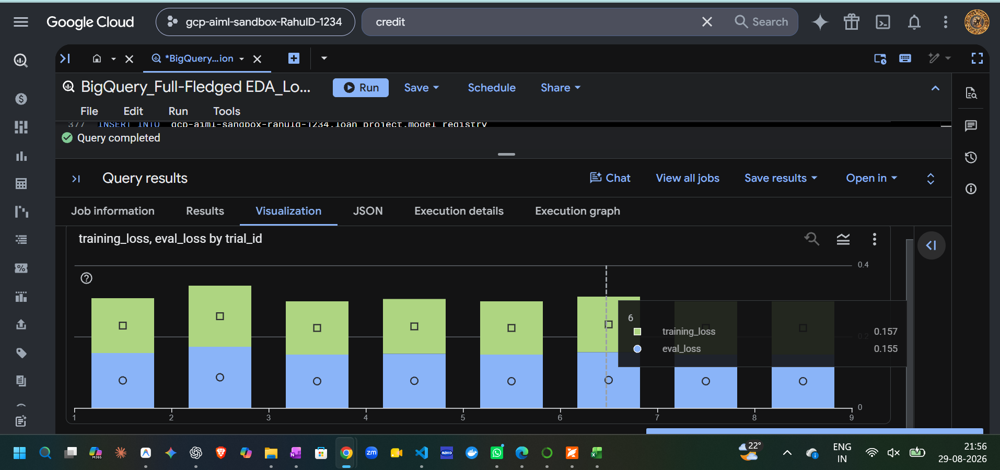


# PHASE 8: Batch Predictions & Prediction Logging

## 8A. Save Predictions
```sql
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.loan_project.loan_predictions` AS
SELECT
  ROW_NUMBER() OVER(
    ORDER BY (SELECT prob FROM UNNEST(predicted_Status_probs) WHERE label = '1') DESC
  ) AS risk_rank,
  predicted_Status,
  ROUND((SELECT prob FROM UNNEST(predicted_Status_probs) WHERE label = '1'), 4) AS default_probability,
  loan_amount, income, Credit_Score, LTV, loan_purpose,
  credit_score_tier, ltv_risk_flag,
  'model_xgboost_v2' AS model_used,
  CURRENT_TIMESTAMP() AS scored_at
FROM ML.PREDICT(
  MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`,
  (SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`)
);
```

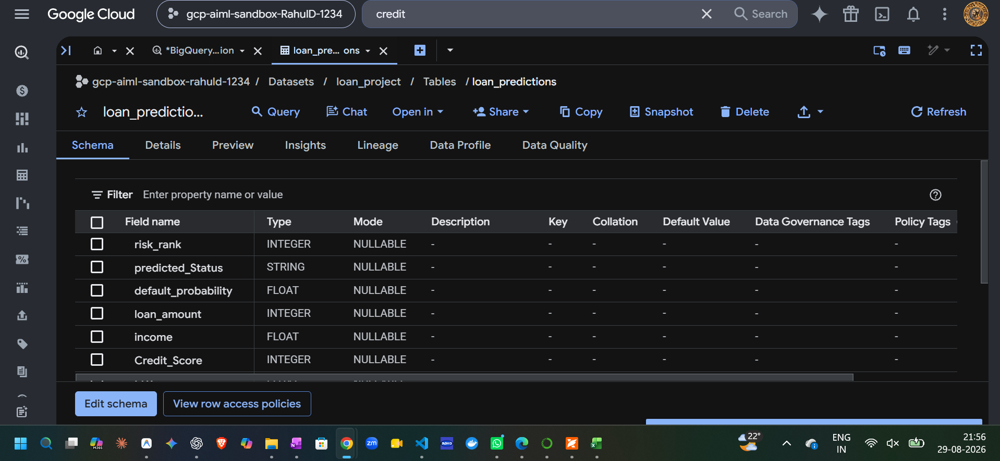

---
## 8B. Log Predictions
```sql
INSERT INTO `gcp-aiml-sandbox-rahuld-1234.loan_project.prediction_logs`
SELECT
  GENERATE_UUID() AS log_id,
  CURRENT_TIMESTAMP() AS request_timestamp,
  'model_xgboost' AS model_used,
  'v2' AS model_version,
  TO_JSON(STRUCT(loan_amount, Credit_Score, LTV)) AS input_features,
  predicted_Status AS predicted_class,
  default_probability AS predicted_probability,
  'BATCH' AS source
FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.loan_predictions`
LIMIT 1000;
```
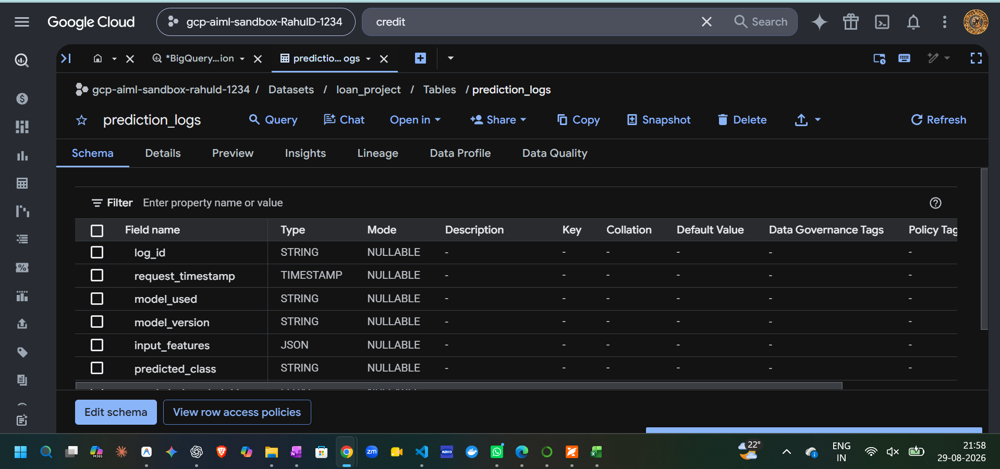

---

## 8C. Top 20 Highest-Risk Loans
```sql
SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.loan_predictions` 
ORDER BY risk_rank LIMIT 20;
```
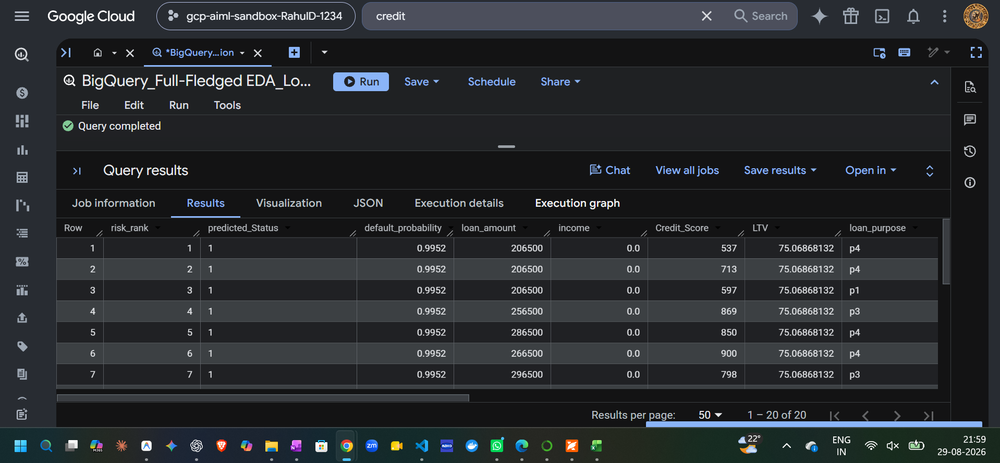

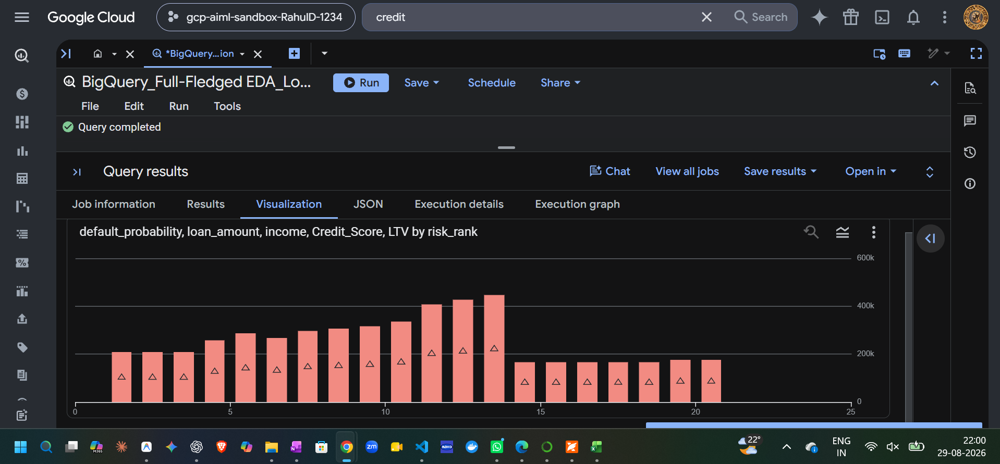

---

# PHASE 9: Model Explainability

## 9A. Global Feature Importance
```sql
WITH feature_stats AS (
  SELECT feature, importance_gain, importance_weight,
    SUM(importance_gain) OVER() AS total_gain
  FROM ML.FEATURE_IMPORTANCE(MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`)
)
SELECT feature,
  ROUND(importance_gain, 4) AS importance_gain,
  ROUND((importance_gain / total_gain) * 100, 2) AS gain_pct_share
FROM feature_stats
ORDER BY importance_gain DESC;
```
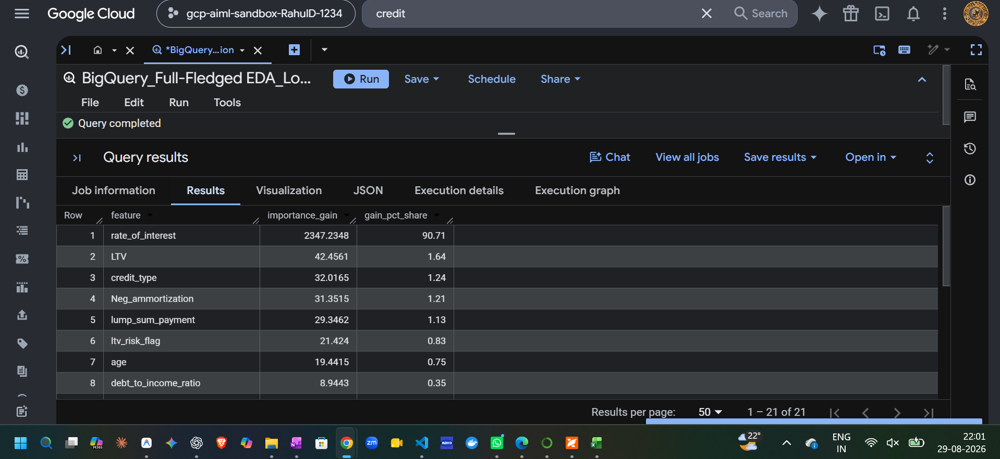

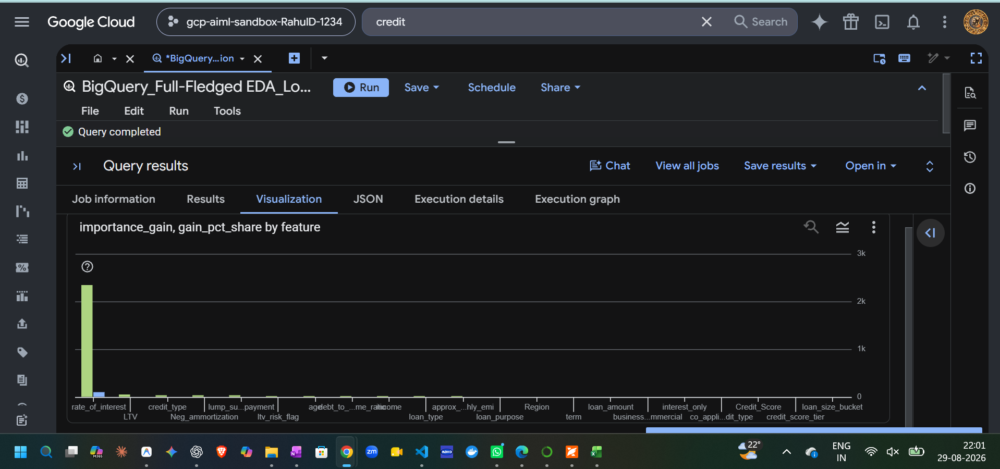

---
## 9B. Local Explainability (Top 3 Drivers per Loan)
```sql
WITH explained AS (
  SELECT
    predicted_Status,
    ROUND(probability, 4) AS confidence,
    loan_amount, income, Credit_Score,
    top_feature_attributions
  FROM ML.EXPLAIN_PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`,
    (SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan` LIMIT 10),
    STRUCT(3 AS top_k_features)
  )
)
SELECT
  predicted_Status, confidence, loan_amount, Credit_Score,
  top_feature_attributions[SAFE_OFFSET(0)].feature AS top_driver_1,
  ROUND(top_feature_attributions[SAFE_OFFSET(0)].attribution, 4) AS driver_1_impact,
  top_feature_attributions[SAFE_OFFSET(1)].feature AS top_driver_2,
  ROUND(top_feature_attributions[SAFE_OFFSET(1)].attribution, 4) AS driver_2_impact,
  top_feature_attributions[SAFE_OFFSET(2)].feature AS top_driver_3,
  ROUND(top_feature_attributions[SAFE_OFFSET(2)].attribution, 4) AS driver_3_impact
FROM explained
ORDER BY confidence DESC;
```
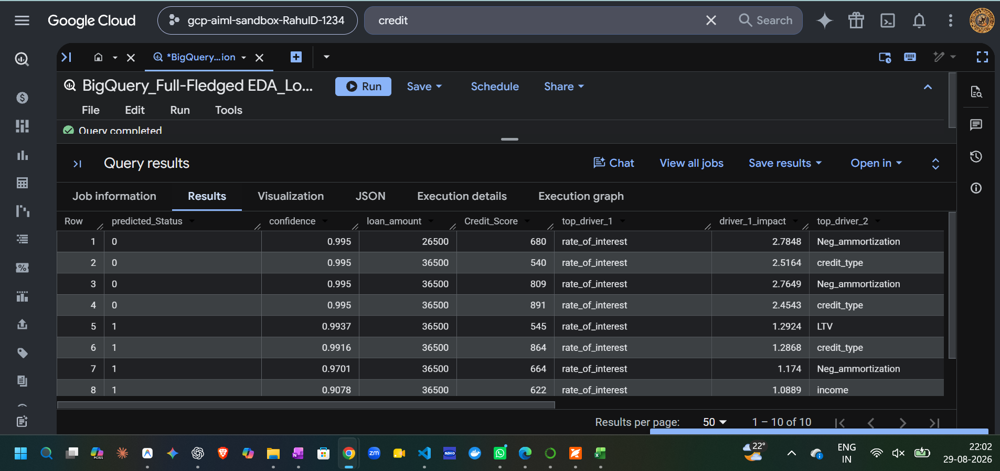

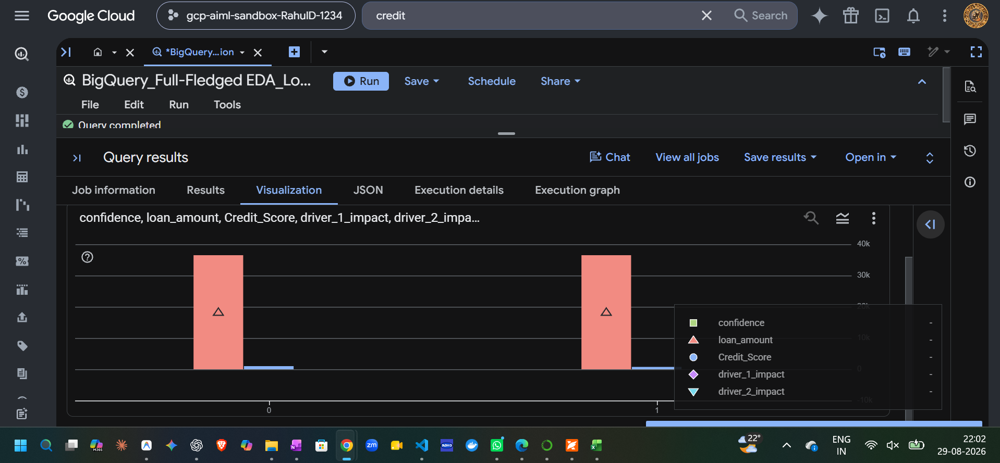

---

# PHASE 10: Flask Prediction API (Python)

## OPTION A: Google Cloud Shell (Easiest — No Setup Required)

### Step 1: Open Cloud Shell
```bash
1. Go to GCP Console
2. Make sure your project gcp-aiml-sandbox-rahuld-1234 is selected (top bar)
3. Click the >_ Activate Cloud Shell icon (top-right corner)
4. Wait ~10 seconds for the terminal to appear at the bottom
```
---
### Step 2: Create a Project Folder
```bash
mkdir loan-api && cd loan-api
```
---
### Step 3: Create requirements.txt
```bash
cat > requirements.txt << 'EOF'
flask==3.0.0
google-cloud-bigquery==3.13.0
gunicorn==21.2.0
EOF
```
---
### Step 4: Create app.py
```bash
cat > app.py << 'PYEOF'
import uuid
import logging
from datetime import datetime
from flask import Flask, request, jsonify, render_template_string
from google.cloud import bigquery

# ============================================================
# Configuration
# ============================================================
PROJECT_ID = "gcp-aiml-sandbox-rahuld-1234"
DATASET = "loan_project"
DEFAULT_MODEL = "model_xgboost_v2"

# ============================================================
# Logging Setup
# ============================================================
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)
logger = logging.getLogger("LoanAPI")

app = Flask(__name__)
bq_client = bigquery.Client(project=PROJECT_ID)


def log_prediction(model_used, version, features, pred_class, pred_prob):
    """Log prediction into BigQuery logs table."""
    try:
        row = [{
            "log_id": str(uuid.uuid4()),
            "request_timestamp": datetime.utcnow().isoformat(),
            "model_used": model_used,
            "model_version": version,
            "input_features": str(features).replace("'", '"'),
            "predicted_class": str(pred_class),
            "predicted_probability": float(pred_prob),
            "source": "API"
        }]
        bq_client.insert_rows_json(f"{PROJECT_ID}.{DATASET}.prediction_logs", row)
    except Exception as e:
        logger.error(f"Logging failed: {e}")


# ============================================================
# ROUTE 1: Home Dashboard (For Browser Web Preview)
# ============================================================
@app.route("/", methods=["GET"])
def home():
    return render_template_string("""
    <!DOCTYPE html>
    <html>
    <head>
      <title>Loan Default Prediction API</title>
      <style>
        body { font-family: Arial, sans-serif; margin: 40px; background: #f4f6f9; color: #333; }
        .card { background: white; padding: 25px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); max-width: 700px; }
        h2 { color: #1a73e8; }
        code { background: #eee; padding: 2px 6px; border-radius: 4px; }
        a { color: #1a73e8; text-decoration: none; font-weight: bold; }
        ul { line-height: 1.8; }
      </style>
    </head>
    <body>
      <div class="card">
        <h2>🚀 Loan Default Prediction API is Online!</h2>
        <p>BigQuery ML backend is connected to project: <code>gcp-aiml-sandbox-rahuld-1234</code></p>
        <h3>Available Endpoints:</h3>
        <ul>
          <li><a href="/health">GET /health</a> - Health status check</li>
          <li><a href="/models">GET /models</a> - List all trained model versions</li>
          <li><a href="/logs">GET /logs</a> - View recent prediction logs</li>
          <li><code>POST /predict</code> - Send JSON payload to predict loan default risk</li>
        </ul>
      </div>
    </body>
    </html>
    """), 200


# ============================================================
# ROUTE 2: Health Check
# ============================================================
@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status": "OK",
        "service": "Loan Default Prediction API",
        "project": PROJECT_ID,
        "active_model": DEFAULT_MODEL
    }), 200


# ============================================================
# ROUTE 3: Predict Endpoint (Strict Type Safety)
# ============================================================
@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = request.get_json(force=True)
        logger.info(f"Incoming predict request: {data}")

        model_name = data.get("model_name", DEFAULT_MODEL)

        # ── Parse inputs with exact types ───────────────────
        la = int(float(data.get("loan_amount", 250000)))
        inc = float(data.get("income", 65000))
        cs = int(float(data.get("Credit_Score", 700)))
        roi = float(data.get("rate_of_interest", 4.5))
        ltv = float(data.get("LTV", 75.0))
        term = float(data.get("term", 360.0))

        # ── Feature Engineering calculations ────────────────
        dti = round(la / max(inc, 1), 4)
        emi = round((la * (1 + roi / 100)) / max(term, 1), 2)

        if cs < 580:   tier = "Poor"
        elif cs < 670: tier = "Fair"
        elif cs < 740: tier = "Good"
        elif cs < 800: tier = "Very Good"
        else:          tier = "Excellent"

        if la <= 100000:   bucket = "Small"
        elif la <= 300000: bucket = "Medium"
        elif la <= 500000: bucket = "Large"
        else:              bucket = "Jumbo"

        ltv_flag = "HighRisk" if ltv > 80 else "LowRisk"

        # ── Query BQML with Explicit CAST() on every column ──
        query = f"""
          SELECT
            predicted_Status,
            ROUND((SELECT prob FROM UNNEST(predicted_Status_probs) WHERE label = '1'), 4) AS default_probability
          FROM ML.PREDICT(
            MODEL `{PROJECT_ID}.{DATASET}.{model_name}`,
            (SELECT
              CAST({la} AS INT64)                          AS loan_amount,
              CAST({inc} AS FLOAT64)                       AS income,
              CAST({cs} AS INT64)                          AS Credit_Score,
              CAST({roi} AS FLOAT64)                       AS rate_of_interest,
              CAST({ltv} AS FLOAT64)                       AS LTV,
              CAST({term} AS FLOAT64)                      AS term,
              CAST('{data.get("loan_type","type1")}' AS STRING)              AS loan_type,
              CAST('{data.get("loan_purpose","p1")}' AS STRING)              AS loan_purpose,
              CAST('{data.get("business_or_commercial","nob/c")}' AS STRING) AS business_or_commercial,
              CAST('{data.get("Neg_ammortization","not_neg")}' AS STRING)    AS Neg_ammortization,
              CAST('{data.get("interest_only","not_int")}' AS STRING)        AS interest_only,
              CAST('{data.get("lump_sum_payment","not_lpsm")}' AS STRING)    AS lump_sum_payment,
              CAST('{data.get("credit_type","EXP")}' AS STRING)              AS credit_type,
              CAST('{data.get("co_applicant_credit_type","CIB")}' AS STRING) AS co_applicant_credit_type,
              CAST('{data.get("age","35-44")}' AS STRING)                    AS age,
              CAST('{data.get("Region","south")}' AS STRING)                 AS Region,
              CAST({dti} AS FLOAT64)                       AS debt_to_income_ratio,
              CAST('{bucket}' AS STRING)                   AS loan_size_bucket,
              CAST('{tier}' AS STRING)                     AS credit_score_tier,
              CAST('{ltv_flag}' AS STRING)                 AS ltv_risk_flag,
              CAST({emi} AS FLOAT64)                       AS approx_monthly_emi
            )
          )
        """

        result = list(bq_client.query(query).result())[0]
        pred_class = str(result["predicted_Status"])
        pred_prob = float(result["default_probability"])

        # Log into BigQuery logs table
        log_prediction(model_name, "v2", data, pred_class, pred_prob)

        return jsonify({
            "success": True,
            "model_used": model_name,
            "predicted_class": pred_class,
            "default_probability": pred_prob,
            "risk_assessment": "HIGH RISK OF DEFAULT" if pred_prob > 0.5 else "LOW RISK (SAFE LOAN)"
        }), 200

    except Exception as e:
        logger.error(f"Prediction execution failed: {e}")
        return jsonify({"success": False, "error": str(e)}), 500


# ============================================================
# ROUTE 4: Model Registry Listing
# ============================================================
@app.route("/models", methods=["GET"])
def list_models():
    try:
        rows = [dict(r) for r in bq_client.query(f"""
          SELECT model_name, version, model_type, training_timestamp, status, notes
          FROM `{PROJECT_ID}.{DATASET}.model_registry`
          ORDER BY training_timestamp DESC
        """).result()]
        return jsonify({"registered_models": rows}), 200
    except Exception as e:
        return jsonify({"error": str(e)}), 500


# ============================================================
# ROUTE 5: Prediction Logs
# ============================================================
@app.route("/logs", methods=["GET"])
def get_logs():
    try:
        rows = [dict(r) for r in bq_client.query(f"""
          SELECT log_id, request_timestamp, model_used, model_version,
                 predicted_class, predicted_probability, source
          FROM `{PROJECT_ID}.{DATASET}.prediction_logs`
          ORDER BY request_timestamp DESC LIMIT 15
        """).result()]
        return jsonify({"recent_prediction_logs": rows}), 200
    except Exception as e:
        return jsonify({"error": str(e)}), 500


if __name__ == "__main__":
    logger.info("Starting Loan Default Prediction API on port 8080...")
    app.run(host="0.0.0.0", port=8080, debug=False)
PYEOF
```
---

### Step 5: Install Dependencies
```bash
pip install -r requirements.txt
```
---
### Step 6: Start the API
```bash
python app.py
```
---
### Step 7: Test It (Open a NEW Cloud Shell Tab)
> Click the + icon next to your Cloud Shell tab to open a second terminal, then run:
```bash
# Test 1: Health Check
curl http://localhost:8080/health

# Test 2: Predict Loan Default
curl -X POST http://localhost:8080/predict \
  -H "Content-Type: application/json" \
  -d '{
    "loan_amount": 250000,
    "income": 65000,
    "Credit_Score": 720,
    "rate_of_interest": 4.5,
    "LTV": 75,
    "term": 360,
    "loan_purpose": "p2",
    "Region": "south"
  }'

# Test 3: View Model Registry
curl http://localhost:8080/models

# Test 4: View Prediction Logs
curl http://localhost:8080/logs
```
---
### Test the Predict Endpoint
```bash
curl -X POST http://localhost:8080/predict \
  -H "Content-Type: application/json" \
  -d '{
    "loan_amount": 250000,
    "income": 65000,
    "Credit_Score": 720,
    "rate_of_interest": 4.5,
    "LTV": 75,
    "term": 360,
    "loan_purpose": "p2",
    "Region": "south"
  }'
```
---

### Step 8: Web Preview (Browser Testing)
```bash
1. In Cloud Shell, click the Web Preview icon (eye icon, top-right of terminal)
2. Select Preview on port 8080
3. Append /health to the URL in your browser
```
---

# PHASE 11: Cleanup
```sql
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_logistic_v1`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_random_forest_v1`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v1`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_xgboost_v2`;

DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.loan_predictions`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_evaluation_reports`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.feature_engineered_loan`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.cleaned_loan`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.prediction_logs`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.training_logs`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.model_registry`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project.raw_loan_default`;

DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.loan_project` CASCADE;
```

# Summary of Enterprise Features Added

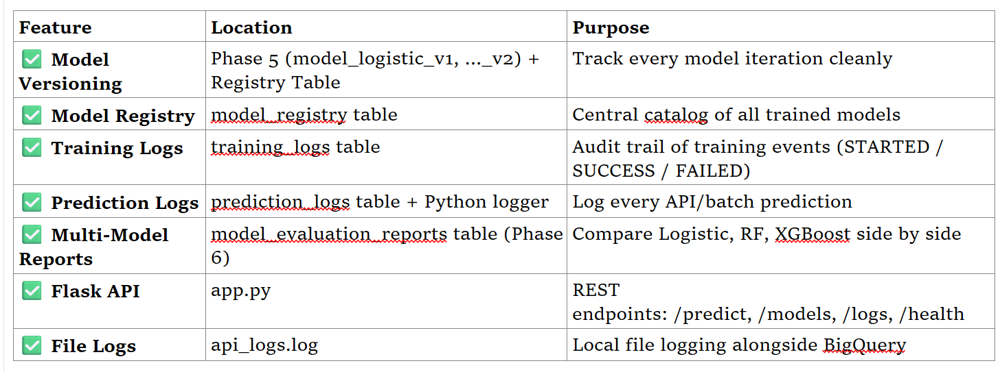